# Topic 2 -- Data Processing

---
**Note: Content extracted from CM3005 course materials (available via Coursera)**

---

---

**Topic Learning Objectives**:
1. Manipulate data with NumPy
2. Use indices to extract sub-tables
3. Use NumPy functionality to obtain statistical information from datasets
4. Perform basic Linear Algebra operations involving vectors and matrices
5. Evaluate determinants, ranks and traces of matrices
6. Use the pandas library to manipulate datasets
7. 
Process and visualise time series data

---

<div style="background:#e7f3fe; padding:10px; border-radius:5px;">
  <h2> 2.2 Data Manipulation with Pandas </h2>
</div>

### 2.2.1 Pandas Series and DataFrame

#### Pandas: Python Data Analysis Library

- Provides data structures and tools for analysis
- Open source
- Very wide used in academia and industry
- Integrates with other packages to enable a complete analysis workflow
    * NumPy
    * SciPy
    * Matplotlib
    * scikit-learn (or sklearn)

#### Core Data Structures

- Series
    * One-dimensional labelled array
    * Data can be any type
- DataFrame
    * Two-dimensional labelled table
    * Columns can be of different types

In [1]:
# Install Pandas (if necessary)
#!pip install pandas  

In [2]:
import pandas as pd
pd.__version__

'2.2.2'

#### Pandas Series

In [3]:
# Create a Pandas Series
s = pd.Series([1,2,3], ['a','b','c'], name='data')
#s = pd.Series([1,2,3], ['a','b','c'])
s

a    1
b    2
c    3
Name: data, dtype: int64

In [4]:
### Insert code to access elements in the Pandas Series

In [5]:
s = pd.Series([1,2,3])
s

0    1
1    2
2    3
dtype: int64

In [6]:
s = pd.Series([1,2,3], ['a','b','c'], name='data')
s

a    1
b    2
c    3
Name: data, dtype: int64

In [7]:
s.index

Index(['a', 'b', 'c'], dtype='object')

In [8]:
s.index.dtype

dtype('O')

In [9]:
s[['a','c']]

a    1
c    3
Name: data, dtype: int64

In [10]:
s.loc[['a','c']]   # label-based indexing

a    1
c    3
Name: data, dtype: int64

In [11]:
s.iloc[[0,2]]   # position-based indexing

a    1
c    3
Name: data, dtype: int64

In [12]:
s

a    1
b    2
c    3
Name: data, dtype: int64

In [19]:
s[s > 1] 

b    2
c    3
Name: data, dtype: int64

In [20]:
s.loc[s > 1]   # boolean indexing

b    2
c    3
Name: data, dtype: int64

In [21]:
s

a    1
b    2
c    3
Name: data, dtype: int64

In [22]:
s * 3

a    3
b    6
c    9
Name: data, dtype: int64

#### Pandas DataFrame

In [23]:
# Create a dataframe using a list (or list of lists)
pd.DataFrame([
    [1, 'a'],
    [2, 'b'],
    [3, 'c']], 
    columns=['col1', 'col2'])

,col1,col2
0,1,a
1,2,b
2,3,c


In [24]:
# Create a dataframe using a dictionary
data = {
    'col1': [1, 2, 3],
    'col2': ['a', 'b', 'c']
}
pd.DataFrame(data)

,col1,col2
0,1,a
1,2,b
2,3,c


In [25]:
# Create some data on student enrolment - with some missing values
# Save data to a file named "class_data.csv"

import pandas as pd
import numpy as np
import os

np.random.seed(101)

# Data pools
gender = ['male', 'female']
programmes = ['Computer Science', 'Statistics', 'Engineering']

# Function to randomly introduce missing values
def introduce_missing(data_list, missing_rate=0.1):
    return [val if np.random.random() > missing_rate else np.nan for val in data_list]

# Number of samples
num_samples = 100

# Set mean and standard deviation for height (e.g., mean = 170 cm, std = 10 cm)
mean_height = 170  # mean height in cm
std_dev_height = 10  # standard deviation in cm

# Generate the data
data = {
    "gender": introduce_missing([np.random.choice(gender) for _ in range(num_samples)]),
    "height": introduce_missing([int(np.random.normal(mean_height, std_dev_height)) for _ in range(num_samples)]),
    "programme": introduce_missing([np.random.choice(programmes) for _ in range(num_samples)]),
}

# Create DataFrame
df = pd.DataFrame(data)

# Save to CSV
if not os.path.exists("class_data.csv"):
    df.to_csv("class_data.csv", index=False)
    print("File saved.")
else:
    print("File exists. Not saved.")

# Preview the data
print(df.head())   

File exists. Not saved.
   gender  height         programme
0  female     NaN  Computer Science
1  female   162.0       Engineering
2     NaN     NaN       Engineering
3    male   153.0       Engineering
4  female   176.0       Engineering


In [26]:
### Insert code to try out some basic functions in the Pandas DataFrame

In [27]:
df = pd.read_csv('class_data.csv')

In [28]:
df.head()

,gender,height,programme
0,female,NaN,Computer Science
1,female,162.0,Engineering
2,NaN,NaN,Engineering
3,male,153.0,Engineering
4,female,176.0,Engineering


In [29]:
df.sample(5)

,gender,height,programme
34,male,181.0,Engineering
37,female,163.0,Engineering
60,female,190.0,Engineering
82,male,167.0,Computer Science
7,female,NaN,Engineering


In [30]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   gender     91 non-null     object 
 1   height     91 non-null     float64
 2   programme  92 non-null     object 
dtypes: float64(1), object(2)
memory usage: 2.5+ KB


In [31]:
df.isna().sum()

gender       9
height       9
programme    8
dtype: int64

In [32]:
df['gender'] = df['gender'].astype('category')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype   
---  ------     --------------  -----   
 0   gender     91 non-null     category
 1   height     91 non-null     float64 
 2   programme  92 non-null     object  
dtypes: category(1), float64(1), object(1)
memory usage: 1.9+ KB


In [33]:
df['gender'].dtype

CategoricalDtype(categories=['female', 'male'], ordered=False, categories_dtype=object)

In [34]:
df.gender.dtype

CategoricalDtype(categories=['female', 'male'], ordered=False, categories_dtype=object)

In [35]:
df.describe()

,height
count,91.000000
mean,169.637363
std,10.573044
min,142.000000
25%,162.000000
50%,170.000000
75%,176.000000
max,194.000000


In [36]:
df.describe(include='all')

,gender,height,programme
count,91,91.000000,92
unique,2,NaN,3
top,female,NaN,Engineering
freq,49,NaN,41
mean,NaN,169.637363,NaN
std,NaN,10.573044,NaN
min,NaN,142.000000,NaN
25%,NaN,162.000000,NaN
50%,NaN,170.000000,NaN
75%,NaN,176.000000,NaN


In [37]:
type(df['gender'])

pandas.core.series.Series

In [38]:
type(df[['gender']])

pandas.core.frame.DataFrame

In [39]:
### Insert code to access elements in the Pandas DataFrame

In [40]:
df.head()

,gender,height,programme
0,female,NaN,Computer Science
1,female,162.0,Engineering
2,NaN,NaN,Engineering
3,male,153.0,Engineering
4,female,176.0,Engineering


In [41]:
df.loc[0]

gender                 female
height                    NaN
programme    Computer Science
Name: 0, dtype: object

In [42]:
df.loc[[0, 2, 5]]

,gender,height,programme
0,female,NaN,Computer Science
2,NaN,NaN,Engineering
5,female,170.0,Computer Science


In [43]:
df.loc[[0, 2, 5], :]

,gender,height,programme
0,female,NaN,Computer Science
2,NaN,NaN,Engineering
5,female,170.0,Computer Science


In [44]:
df.loc[[0, 2, 5],]

,gender,height,programme
0,female,NaN,Computer Science
2,NaN,NaN,Engineering
5,female,170.0,Computer Science


In [45]:
df.iloc[[0,2,5]]

,gender,height,programme
0,female,NaN,Computer Science
2,NaN,NaN,Engineering
5,female,170.0,Computer Science


In [46]:
df.loc[1:5]

,gender,height,programme
1,female,162.0,Engineering
2,NaN,NaN,Engineering
3,male,153.0,Engineering
4,female,176.0,Engineering
5,female,170.0,Computer Science


In [47]:
df.iloc[1:5]

,gender,height,programme
1,female,162.0,Engineering
2,NaN,NaN,Engineering
3,male,153.0,Engineering
4,female,176.0,Engineering


In [48]:
df.iloc[95:, [0,1]]

,gender,height
95,female,165.0
96,male,172.0
97,male,NaN
98,male,179.0
99,male,175.0


In [49]:
df.loc[95:, ['gender','height']]

,gender,height
95,female,165.0
96,male,172.0
97,male,NaN
98,male,179.0
99,male,175.0


In [50]:
df.loc[:3, ['gender','height']]

,gender,height
0,female,NaN
1,female,162.0
2,NaN,NaN
3,male,153.0


In [51]:
df[df['height']>185]

,gender,height,programme
9,female,191.0,NaN
11,male,193.0,Computer Science
31,female,192.0,Engineering
53,female,187.0,Engineering
60,female,190.0,Engineering
69,female,194.0,Statistics
84,NaN,187.0,Engineering


In [52]:
df.loc[df['height']>185]

,gender,height,programme
9,female,191.0,NaN
11,male,193.0,Computer Science
31,female,192.0,Engineering
53,female,187.0,Engineering
60,female,190.0,Engineering
69,female,194.0,Statistics
84,NaN,187.0,Engineering


In [53]:
# Working with Missing Data

In [54]:
df.head()

,gender,height,programme
0,female,NaN,Computer Science
1,female,162.0,Engineering
2,NaN,NaN,Engineering
3,male,153.0,Engineering
4,female,176.0,Engineering


In [55]:
# Check for missing values

In [56]:
df.isna().sum()

gender       9
height       9
programme    8
dtype: int64

In [57]:
df.isnull().sum()

gender       9
height       9
programme    8
dtype: int64

In [58]:
df.notnull().sum()

gender       91
height       91
programme    92
dtype: int64

In [59]:
# Impute missing values (time series)

In [60]:
# UPDATE: Instead of the student data (df) used during the lecture,
# we will create a simple 12-month sales time series (df_sales)
# to demonstrate handling missing values using forward-fill (ffill),
# backward-fill (bfill), etc., which are especially relevant for time series data.

# Generate 12 monthly dates starting from January 2023
dates = pd.date_range("2023-01-01", periods=12, freq="ME")

# Sample monthly sales and profit data (with some missing and negative values)
sales = [2000, np.nan, 2500, 1800, 2200, np.nan, 2600, 2400, 2300, 2100, 2700, np.nan]
profit = [400, -150, np.nan, 280, -100, 380, 500, np.nan, -50, 390, 420, 310]

# Build the DataFrame
df_sales = pd.DataFrame({"sales": sales, "profit": profit}, index=dates)

# Show the DataFrame
print(df_sales)

             sales  profit
2023-01-31  2000.0   400.0
2023-02-28     NaN  -150.0
2023-03-31  2500.0     NaN
2023-04-30  1800.0   280.0
2023-05-31  2200.0  -100.0
2023-06-30     NaN   380.0
2023-07-31  2600.0   500.0
2023-08-31  2400.0     NaN
2023-09-30  2300.0   -50.0
2023-10-31  2100.0   390.0
2023-11-30  2700.0   420.0
2023-12-31     NaN   310.0


In [61]:
df_sales.head()

,sales,profit
2023-01-31,2000.0,400.0
2023-02-28,NaN,-150.0
2023-03-31,2500.0,NaN
2023-04-30,1800.0,280.0
2023-05-31,2200.0,-100.0


In [62]:
df_sales.ffill()

,sales,profit
2023-01-31,2000.0,400.0
2023-02-28,2000.0,-150.0
2023-03-31,2500.0,-150.0
2023-04-30,1800.0,280.0
2023-05-31,2200.0,-100.0
2023-06-30,2200.0,380.0
2023-07-31,2600.0,500.0
2023-08-31,2400.0,500.0
2023-09-30,2300.0,-50.0
2023-10-31,2100.0,390.0


In [63]:
df_sales.bfill()

,sales,profit
2023-01-31,2000.0,400.0
2023-02-28,2500.0,-150.0
2023-03-31,2500.0,280.0
2023-04-30,1800.0,280.0
2023-05-31,2200.0,-100.0
2023-06-30,2600.0,380.0
2023-07-31,2600.0,500.0
2023-08-31,2400.0,-50.0
2023-09-30,2300.0,-50.0
2023-10-31,2100.0,390.0


In [64]:
df_sales.head()

,sales,profit
2023-01-31,2000.0,400.0
2023-02-28,NaN,-150.0
2023-03-31,2500.0,NaN
2023-04-30,1800.0,280.0
2023-05-31,2200.0,-100.0


In [66]:
df_sales['sales'].interpolate(method='linear')

2023-01-31    2000.0
2023-02-28    2250.0
2023-03-31    2500.0
2023-04-30    1800.0
2023-05-31    2200.0
2023-06-30    2400.0
2023-07-31    2600.0
2023-08-31    2400.0
2023-09-30    2300.0
2023-10-31    2100.0
2023-11-30    2700.0
2023-12-31    2700.0
Freq: ME, Name: sales, dtype: float64

In [67]:
# Impute missing value (non time series)

In [68]:
# NOTE: We will revert to using the student data (df) for this section,
# instead of the sales time series created earlier.

In [69]:
df.head()

,gender,height,programme
0,female,NaN,Computer Science
1,female,162.0,Engineering
2,NaN,NaN,Engineering
3,male,153.0,Engineering
4,female,176.0,Engineering


In [70]:
df['height'].fillna(200)

0     200.0
1     162.0
2     200.0
3     153.0
4     176.0
      ...  
95    165.0
96    172.0
97    200.0
98    179.0
99    175.0
Name: height, Length: 100, dtype: float64

In [71]:
df['height'].fillna(df['height'].mean())

0     169.637363
1     162.000000
2     169.637363
3     153.000000
4     176.000000
         ...    
95    165.000000
96    172.000000
97    169.637363
98    179.000000
99    175.000000
Name: height, Length: 100, dtype: float64

In [72]:
df['height'].fillna(df['height'].median())

0     170.0
1     162.0
2     170.0
3     153.0
4     176.0
      ...  
95    165.0
96    172.0
97    170.0
98    179.0
99    175.0
Name: height, Length: 100, dtype: float64

In [73]:
df['height'].mode()

0    153.0
1    172.0
2    173.0
3    176.0
Name: height, dtype: float64

In [74]:
df['height'].fillna(df['height'].mode()[0])

0     153.0
1     162.0
2     153.0
3     153.0
4     176.0
      ...  
95    165.0
96    172.0
97    153.0
98    179.0
99    175.0
Name: height, Length: 100, dtype: float64

In [75]:
# Drop rows with missing values

In [76]:
df.dropna()

,gender,height,programme
1,female,162.0,Engineering
3,male,153.0,Engineering
4,female,176.0,Engineering
5,female,170.0,Computer Science
6,female,153.0,Statistics
...,...,...,...
94,male,182.0,Computer Science
95,female,165.0,Engineering
96,male,172.0,Statistics
98,male,179.0,Engineering


In [77]:
df.dropna(subset=['gender','height'])

,gender,height,programme
1,female,162.0,Engineering
3,male,153.0,Engineering
4,female,176.0,Engineering
5,female,170.0,Computer Science
6,female,153.0,Statistics
...,...,...,...
94,male,182.0,Computer Science
95,female,165.0,Engineering
96,male,172.0,Statistics
98,male,179.0,Engineering


In [78]:
df['height'].dropna()

1     162.0
3     153.0
4     176.0
5     170.0
6     153.0
      ...  
94    182.0
95    165.0
96    172.0
98    179.0
99    175.0
Name: height, Length: 91, dtype: float64

### 2.2.2 Time Series

- Change over time
- Line graphs are most common method
- Sequence of variable measurements, indexed by time, e.g., London population
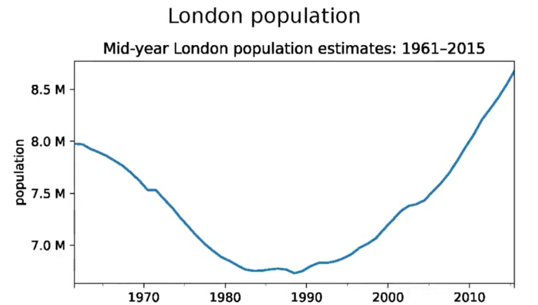

#### Uses and Applications
- Business and finance: Analysis of stock price, costs, profit, unit sold, etc.
- Organisational: Monitoring process or quality, workload projections
- Government and policy making: Changes in economics, health, crime statistics
- Science and engineering: Signal processing, energy efficiency, cell mutation, etc.
- Anything involving measurements over time

#### Looking for Trends
- Seasonal variation
- Significant events: Natural disasters, changes of government, tax regulation, etc.
- Correlations: Do variable change in similar ways over time?
- Understanding the past
- Predicting the future

#### Different Kinds of Patterns
- Variability
- Rate of change
- Co-variance and correlation
- Cycles
- Exceptions

#### Sampling Rate
- Some variables are constantly changing over time, e.g., temperature, physiological response, stock market
- Rate of measurement is important
    * Temperature: one measurement per hour, or one measurement per second?
    * Stock market: trend over a whole year, or changes over milliseconds?
- Depends on application and/or research questions

#### Time-Related Concepts in Pandas
- **Date times**: A specific date and time with timezone support
- **Time deltas**: An absolute time duration
- **Time spans**: A span of time defined by a point in time and its associated frequency
- **Date offsets**: A relative time duration that respects calendar arithmetic

  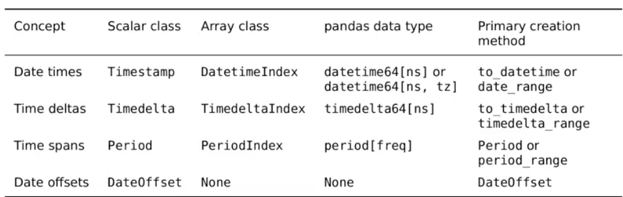

  ###### Source: pandas user guide: time series / date functionality

In [79]:
### Insert code to try out time-related functions

In [80]:
print(pd.Timestamp('2020'))
print(pd.Timestamp('2020-02-25'))
print(pd.Timestamp('2020-02-25, 09:30'))

2020-01-01 00:00:00
2020-02-25 00:00:00
2020-02-25 09:30:00


In [83]:
print(pd.Timestamp('16/01/2020'))  # pandas infers format as DD/MM/YYYY

2020-01-16 00:00:00


In [84]:
print(pd.Timestamp(year=2020, month=1, day=16))

2020-01-16 00:00:00


In [85]:
print(pd.Timestamp('10/02/2020'))  # pandas infers format as MM/DD/YYYY

2020-10-02 00:00:00


In [86]:
print(pd.to_datetime('10/02/2020', dayfirst=True))

2020-02-10 00:00:00


In [87]:
print(pd.to_datetime('10/04/05', yearfirst=True))

2010-04-05 00:00:00


In [88]:
print(pd.to_datetime('2 5 1990', format='%d %m %Y'))

1990-05-02 00:00:00


In [89]:
# Generate sequences of Timestamps

In [90]:
pd.to_datetime(['2020-01-01', '2020-01-02', '2020-01-03'])

DatetimeIndex(['2020-01-01', '2020-01-02', '2020-01-03'], dtype='datetime64[ns]', freq=None)

In [91]:
index = pd.to_datetime(['2020-01-01', '2020-01-02', '2020-01-03'])
index.inferred_freq

'D'

In [92]:
index = pd.to_datetime(['2020-01-01', '2020-01-03', '2020-01-05'])
index.inferred_freq

'2D'

In [95]:
index = pd.to_datetime(['2020-01-01', '2020-01-03', '2020-01-05'])
index.freq = '2D'
# index.freq = 'D'   # throws error

In [96]:
df = pd.DataFrame({'year':[2015,2016],
                   'month':[2,3],
                   'day':[4,5],
                   'hour':[2,3]})

In [97]:
pd.to_datetime(df[['year','month','day','hour']])

0   2015-02-04 02:00:00
1   2016-03-05 03:00:00
dtype: datetime64[ns]

In [98]:
pd.date_range('2020-01-01','2020-01-15', freq='2D')

DatetimeIndex(['2020-01-01', '2020-01-03', '2020-01-05', '2020-01-07',
               '2020-01-09', '2020-01-11', '2020-01-13', '2020-01-15'],
              dtype='datetime64[ns]', freq='2D')

In [99]:
pd.date_range('2020-01-01 00:00:00', periods=5, freq='8h')

DatetimeIndex(['2020-01-01 00:00:00', '2020-01-01 08:00:00',
               '2020-01-01 16:00:00', '2020-01-02 00:00:00',
               '2020-01-02 08:00:00'],
              dtype='datetime64[ns]', freq='8h')

In [101]:
# Time as index
s = pd.Series(range(3),
             index=pd.date_range('2000', freq='D', periods=3))
s

2000-01-01    0
2000-01-02    1
2000-01-03    2
Freq: D, dtype: int64

In [102]:
# Time as data
s = pd.Series(pd.date_range('2000', freq='D', periods=3))
s

0   2000-01-01
1   2000-01-02
2   2000-01-03
dtype: datetime64[ns]

In [103]:
pd.Timestamp(pd.NaT)

NaT

In [104]:
print(pd.isna(pd.NaT))
print(pd.isnull(pd.NaT))

True
True


In [105]:
# Examples of Different Time Concepts

In [106]:
# 1. TIMESTAMP
dt = pd.Timestamp('2025-01-01')
print('Original date: ', dt)

Original date:  2025-01-01 00:00:00


In [107]:
# 2. TIMEDELTA
delta = pd.Timedelta(days=5)
print('Add Timedelta:: ', dt + delta)

Add Timedelta::  2025-01-06 00:00:00


In [108]:
# 3. DATEOFFSET
offset = pd.DateOffset(months=1)
print('Add DateOffset: ', dt + offset)

Add DateOffset:  2025-02-01 00:00:00


In [109]:
# 4. PERIOD
p = pd.Period('2025-07', freq='M')   # freq option: 'Y' for year, 'Q' for quarter
print('Period: ', p)
print('Start: ', p.start_time)
print('End: ', p.end_time)

Period:  2025-07
Start:  2025-07-01 00:00:00
End:  2025-07-31 23:59:59.999999999


### 2.2.3 Time Series Analysis

#### Time Series Analysis - Summing Variables

Download dataset (xlsx file) from London Datastore -- https://data.london.gov.uk/dataset/historic-census-population.  Then rename file to 'population.xlsx'

Alternatively, you can load the Excel (xlsx) file directly from 'https://data.london.gov.uk/download/227f750f-69ab-4605-8e30-1f0ca6744527/2c7867e5-3682-4fdd-8b9d-c63e289b92a6/population%201801%20to%202021.xlsx'


In [110]:
import pandas as pd

# Load the downloaded and renamed dataset
# df = pd.read_excel('population.xlsx', sheet_name='data', header=0, skiprows=range(1,35), nrows=3)

# Load the dataset directly from the website
url = 'https://data.london.gov.uk/download/227f750f-69ab-4605-8e30-1f0ca6744527/2c7867e5-3682-4fdd-8b9d-c63e289b92a6/population%201801%20to%202021.xlsx'
df = pd.read_excel(url, sheet_name='data', header=0, skiprows=range(1,35), nrows=3)

# Set 'area' as index
df.set_index('area', inplace=True)

# Sum the populations for Central London and Rest of Inner London for each year
inner_london = df.loc['Central London'] + df.loc['Rest of Inner London']

# Add the combined data back into the DataFrame as 'inner'
df.loc['inner'] = inner_london

# Rename 'Outer London' to 'outer'
df.rename(index={'Outer London': 'outer'}, inplace=True)

# Keep only 'inner' and 'outer' rows
df = df.loc[['inner', 'outer']]

# Display the filtered DataFrame
df

,1801,1811,1821,1831,1841,1851,1861,1871,1881,1891,...,1931,1939,1951,1961,1971,1981,1991,2001,2011,2021
area,,,,,,,,,,,,,,,,,,,,,
inner,916000,1083000,1311000,1574000,1844000,2219000,2620000,3052000,3625000,4090000,...,4442212,4048000,3331734,3161207,2744159,2228324,2296849,2537910,2978386,3164602
outer,181000,220000,262000,304000,363000,432000,568000,789000,1088000,1482000,...,3668644,4567000,4865073,4835887,4708184,4380274,4382850,4634147,5195555,5635125


In [111]:
# Melt the DataFrame: Converts the years into a single column and each area as its own value
df_melted = df.reset_index().melt(id_vars='area', var_name='year', value_name='population')
print(df_melted.head(),'\n')

# Now, pivot the DataFrame: 'year' as index and 'area' as columns
df_pivoted = df_melted.pivot(index='year', columns='area', values='population')
print(df_pivoted.head())


    area  year  population
0  inner  1801      916000
1  outer  1801      181000
2  inner  1811     1083000
3  outer  1811      220000
4  inner  1821     1311000 

area    inner   outer
year                 
1801   916000  181000
1811  1083000  220000
1821  1311000  262000
1831  1574000  304000
1841  1844000  363000


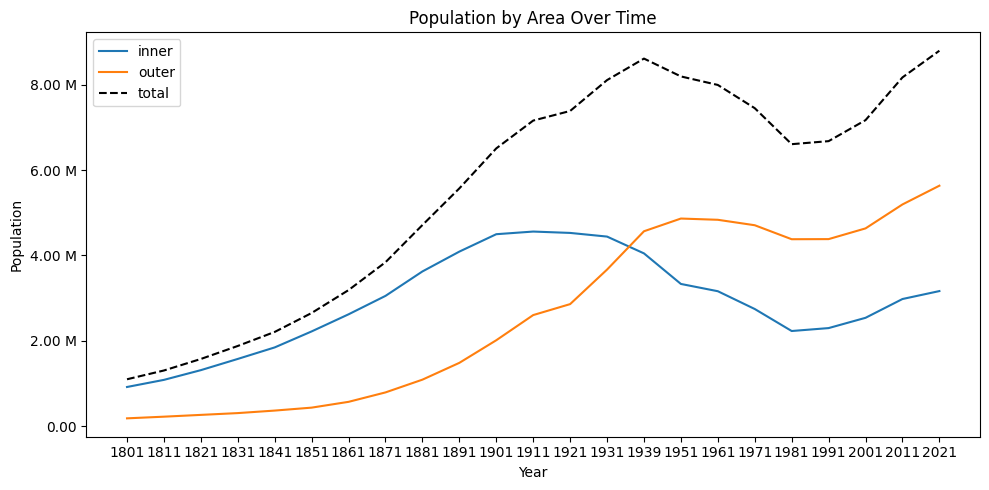

In [112]:
import matplotlib.pyplot as plt
import matplotlib as mpl

# Create the plot
plt.figure(figsize=(10, 5))

# Plot each area's line
for area in df_pivoted.columns:
    plt.plot(df_pivoted.index, df_pivoted[area], label=area)

# Plot the total of 'inner' and 'outer'
plt.plot(
    df_pivoted.index,
    df_pivoted['inner'] + df_pivoted['outer'],
    label='total',
    color='black',
    linestyle='--'
)

# Add labels, title, and legend
plt.title('Population by Area Over Time')
plt.xlabel('Year')
plt.ylabel('Population')
plt.legend()

# Format y-axis to avoid scientific notation (e.g., use "1M" instead of "1e6")
plt.gca().yaxis.set_major_formatter(mpl.ticker.EngFormatter(places=2))

# Final layout and display
plt.tight_layout()
plt.show()


#### Time Series Analysis - Difference Between Variables

In [113]:
# Set multi-level index
df_melted.set_index(['year', 'area'], inplace=True)
df_melted.head()

population
year area             
1801 inner      916000
     outer      181000
1811 inner     1083000
     outer      220000
1821 inner     1311000

In [114]:
# Calculate difference between variables
difference = (df_melted.xs('outer', level='area') -
              df_melted.xs('inner', level='area'))
difference.name = 'difference'
difference.head()

,population
year,
1801,-735000
1811,-863000
1821,-1049000
1831,-1270000
1841,-1481000


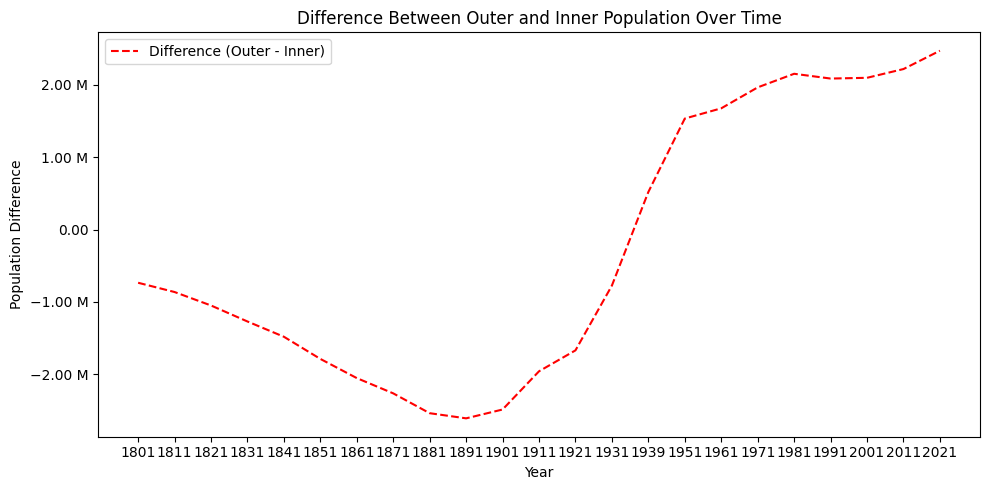

In [115]:
plt.figure(figsize=(10, 5)) 

# Plot the difference (outer - inner)
plt.plot(difference.index, 
         difference, 
         label='Difference (Outer - Inner)', 
         linestyle='--', 
         color='red')

# Add title and labels
plt.title('Difference Between Outer and Inner Population Over Time')
plt.xlabel('Year')
plt.ylabel('Population Difference')
plt.gca().yaxis.set_major_formatter(mpl.ticker.EngFormatter(places=2))

# Add legend
plt.legend()

# Disable gridlines if not needed
plt.grid(False)

# Ensure the layout is tight and show the plot
plt.tight_layout()
plt.show()

In [116]:
# Find the maximum difference value
difference.max()

population    2470523
dtype: int64

In [117]:
# Find the year in which the difference was biggest
max_year = difference.idxmax()
max_year

population    2021
dtype: object

In [118]:
df_melted.loc[max_year]

population
year area             
2021 inner     3164602
     outer     5635125

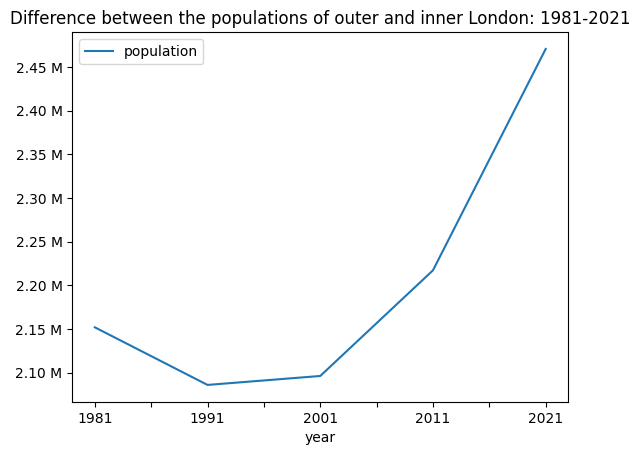

In [119]:
# Slice data from 1981 to 2021
ax = difference.loc['1981':].plot()
ax.set_title('''Difference between the populations of outer and inner London: 1981-2021''')
ax.yaxis.set_major_formatter(mpl.ticker.EngFormatter(places=2))
plt.show()

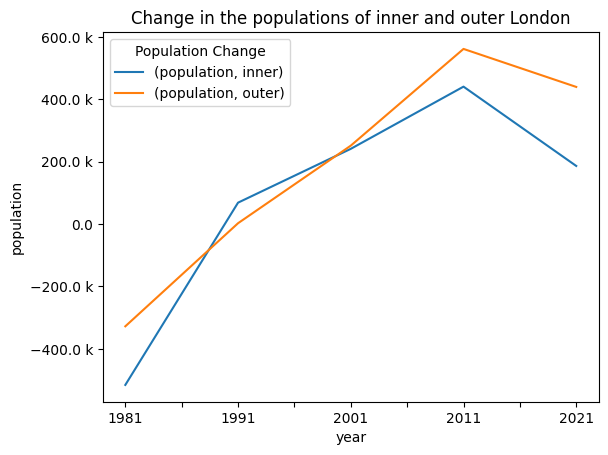

In [120]:
# Year-on-year change
# diff() method calculates change between observations

# ax = df_melted.unstack('area').diff().plot()
ax = df_melted.unstack('area').diff().loc['1981':].plot()
ax.set_title('''Change in the populations of inner and outer London''')
ax.yaxis.set_major_formatter(mpl.ticker.EngFormatter(places=1))
ax.set_ylabel('population')
ax.legend(title="Population Change")
plt.show()

In [121]:
df_melted.head()

population
year area             
1801 inner      916000
     outer      181000
1811 inner     1083000
     outer      220000
1821 inner     1311000

In [122]:
df_melted.unstack('area').head()

population        
area      inner   outer
year                   
1801     916000  181000
1811    1083000  220000
1821    1311000  262000
1831    1574000  304000
1841    1844000  363000

In [123]:
df_melted.unstack('area').diff().head()

population         
area      inner    outer
year                    
1801        NaN      NaN
1811   167000.0  39000.0
1821   228000.0  42000.0
1831   263000.0  42000.0
1841   270000.0  59000.0

In [124]:
df_melted.unstack('area').diff().loc['1981':].head()

population          
area      inner     outer
year                     
1981  -515835.0 -327910.0
1991    68525.0    2576.0
2001   241061.0  251297.0
2011   440476.0  561408.0
2021   186216.0  439570.0

#### Time Series Analysis - Rolling Correlation

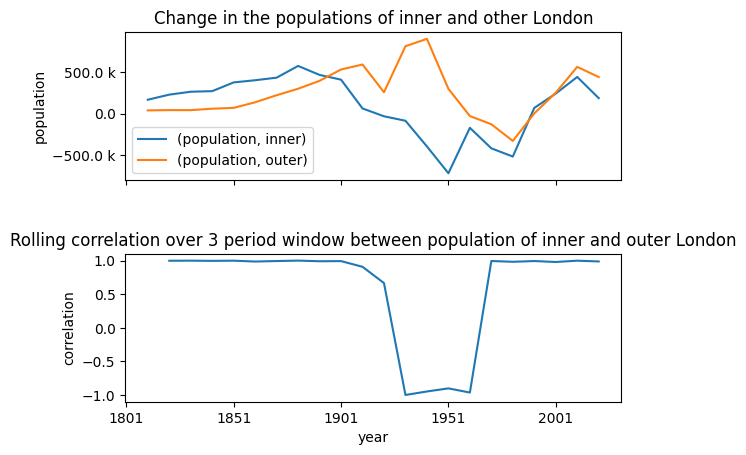

In [125]:
# Rolling correlation between inner and outer London

fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True)

# Change on top plot
ax1 = df_melted.unstack('area').diff().plot(ax=ax1)
ax1.yaxis.set_major_formatter(mpl.ticker.EngFormatter(places=1))
ax1.set_title('Change in the populations of inner and other London')
ax1.set_ylabel('population')
ax1.legend(title=None)

# Correlation on bottom plot
# Create windowed correlation between inner and outer
c = df_pivoted.loc[:, 'inner'].rolling(window=3).corr(df_pivoted.loc[:, 'outer'])
# Plot the relationship
c.plot(ax=ax2)

# Adjust y-axis range
ax2.set_ylim(-1.1, 1.1)
ax2.set_title('''Rolling correlation over 3 period window between population of inner and outer London''')
ax2.set_ylabel('correlation')
fig.subplots_adjust(hspace=0.5)
plt.show()

In [126]:
df_pivoted.head()

area,inner,outer
year,,
1801,916000,181000
1811,1083000,220000
1821,1311000,262000
1831,1574000,304000
1841,1844000,363000


In [127]:
df_pivoted.loc[:, 'inner'].rolling(window=3).corr(df_pivoted.loc[:, 'outer'])

year
1801         NaN
1811         NaN
1821    0.997720
1831    0.999154
1841    0.996016
1851    0.998817
1861    0.986061
1871    0.993380
1881    0.999985
1891    0.990358
1901    0.992512
1911    0.907789
1921    0.665513
1931   -0.999459
1939   -0.947568
1951   -0.901377
1961   -0.963468
1971    0.993940
1981    0.982493
1991    0.993305
2001    0.979372
2011    0.998776
2021    0.987238
dtype: float64

#### Time Series Analysis - Testing for Randomness

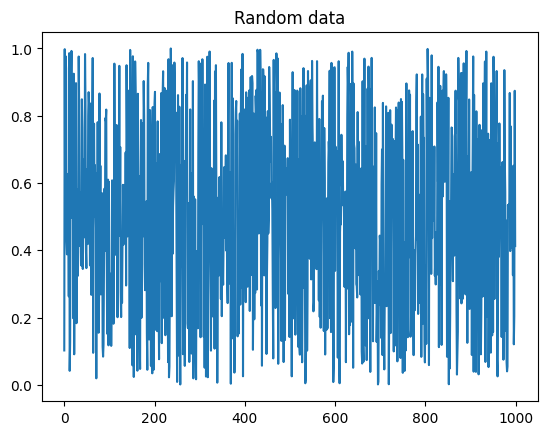

In [128]:
# Testing for randomness
import numpy as np

ax = pd.Series(np.random.rand(1000)).plot()
ax.set_title('Random data')
plt.show()

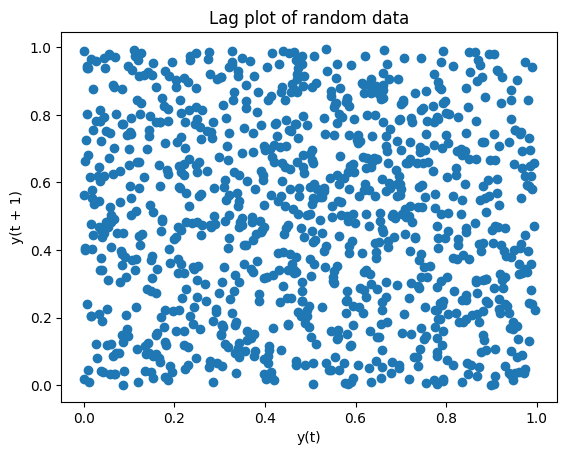

In [129]:
# Testing for randomness: Lag plot of random data
from pandas.plotting import lag_plot

ax = lag_plot(pd.Series(np.random.rand(1000)))
# ax = lag_plot(pd.Series(np.random.rand(1000)), lag=2)  # Default lag=1
ax.set_title('Lag plot of random data')
plt.show()

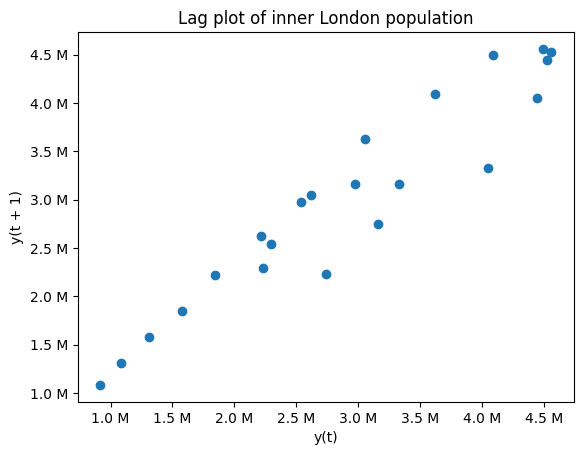

In [130]:
# Testing for randomness: Lag plot of inner London population
from pandas.plotting import lag_plot

ax = lag_plot(df_pivoted.loc[:, 'inner'])
ax.set_title('Lag plot of inner London population')
ax.xaxis.set_major_formatter(mpl.ticker.EngFormatter(places=1))
ax.yaxis.set_major_formatter(mpl.ticker.EngFormatter(places=1))
plt.show()

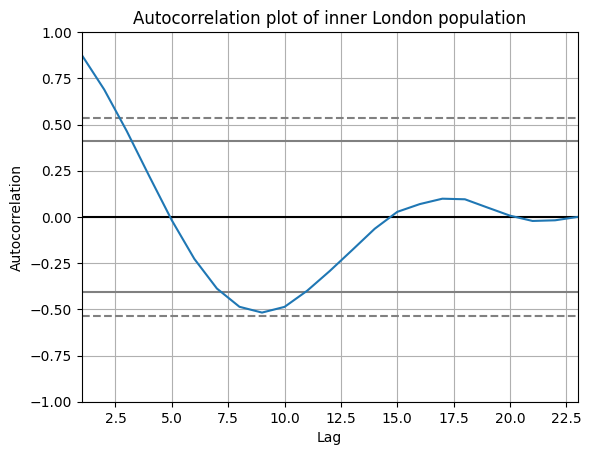

In [131]:
# Testing for randomness: Autocorrelation plot of inner London population
from pandas.plotting import autocorrelation_plot

ax = autocorrelation_plot(df_pivoted.loc[:, 'inner']) 
ax.set_title('Autocorrelation plot of inner London population')
plt.show()

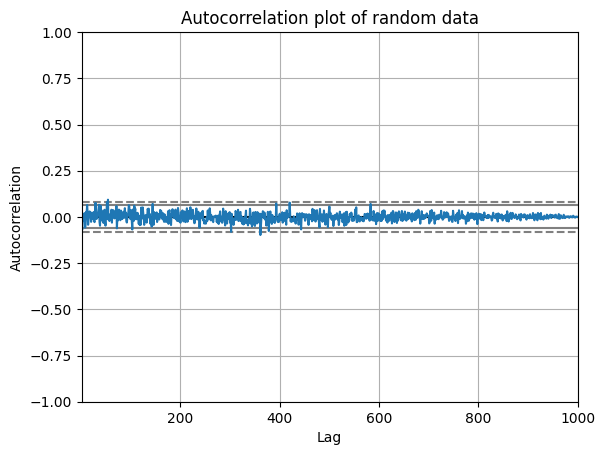

In [132]:
# Testing for randomness: Autocorrelation plot of random data
from pandas.plotting import autocorrelation_plot

ax = autocorrelation_plot(pd.Series(np.random.rand(1000))) 
ax.set_title('Autocorrelation plot of random data')
plt.show()